In [1]:
import pandas as pd
import psycopg2
from dotenv import load_dotenv
import os

load_dotenv()
conn = psycopg2.connect(os.environ["DATABASE_URL"])

df = pd.read_sql("SELECT * FROM books_clean;", conn)
df.shape

C:\Users\QUEEN\AppData\Local\Temp\ipykernel_20948\2037158974.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("SELECT * FROM books_clean;", conn)


(1940, 9)

In [2]:
print(df.shape)
df.head()

(1940, 9)


,book_id,title,primary_author,published_year,page_count,primary_category,language,avg_rating,ratings_count
0,MoxfAAAAMAAJ,Lives of the Caesars,Suetonius,2000.0,458.0,History,en,NaN,NaN
1,870_AQAAIAAJ,Dictionary of Greek and Roman Biography and My...,William Smith,1846.0,1238.0,Biography,en,NaN,NaN
2,wQbhm8wRvs8C,Women on the Margins,Natalie Zemon Davis,1995.0,402.0,Biography & Autobiography,en,5.0,1.0
3,t1lBAQAAMAAJ,A Classical Dictionary of Greek and Roman Biog...,Sir William Smith,1909.0,1034.0,Biography,en,NaN,NaN
4,zzzTyRV6zkYC,My Heart is My Own,John Alexander Guy,2004.0,612.0,Biography & Autobiography,en,1.0,1.0


In [3]:
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Shape: (1940, 9)

Data types:
 book_id                 str
title                   str
primary_author          str
published_year      float64
page_count          float64
primary_category        str
language                str
avg_rating          float64
ratings_count       float64
dtype: object

Missing values:
 book_id                0
title                  0
primary_author        56
published_year         6
page_count           263
primary_category     235
language               0
avg_rating          1757
ratings_count       1757
dtype: int64

Duplicate rows: 0


In [4]:
import matplotlib.pyplot as plt

# Numeric columns
df[["published_year", "page_count", "avg_rating", "ratings_count"]].describe()

Matplotlib is building the font cache; this may take a moment.


,published_year,page_count,avg_rating,ratings_count
count,1934.000000,1677.000000,183.000000,183.000000
mean,1995.501034,352.488968,4.024590,3.967213
std,30.169957,273.311790,1.027478,13.307398
min,1795.000000,6.000000,1.000000,1.000000
25%,1989.000000,216.000000,3.500000,1.000000
50%,2004.000000,312.000000,4.000000,1.000000
75%,2014.000000,435.000000,5.000000,2.500000
max,2026.000000,7800.000000,5.000000,147.000000


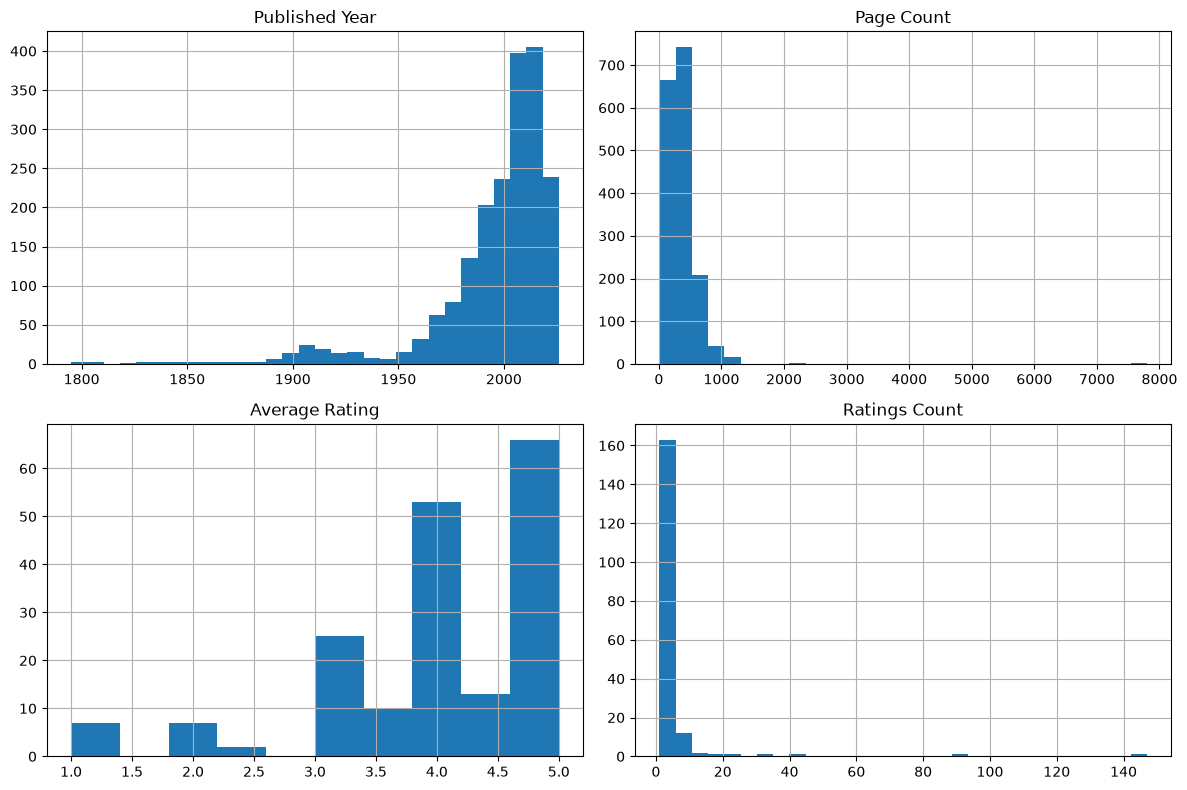

In [5]:
# Histograms
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
df["published_year"].hist(ax=axes[0,0], bins=30)
axes[0,0].set_title("Published Year")

df["page_count"].hist(ax=axes[0,1], bins=30)
axes[0,1].set_title("Page Count")

df["avg_rating"].hist(ax=axes[1,0], bins=10)
axes[1,0].set_title("Average Rating")

df["ratings_count"].hist(ax=axes[1,1], bins=30)
axes[1,1].set_title("Ratings Count")

plt.tight_layout()
plt.show()

In [6]:
# Categorical columns
print(df["primary_category"].value_counts().head(15))
print("\n")
print(df["language"].value_counts())

primary_category
Fiction                      281
History                      122
Biography & Autobiography     82
Juvenile Fiction              70
Philosophy                    68
Business & Economics          67
Cooking                       63
Science                       55
Psychology                    55
Business                      37
Poetry                        35
Travel                        29
Medical                       27
Biography                     26
Education                     26
Name: count, dtype: int64


language
en       1920
es          5
de          4
fr          4
it          2
id          1
ko          1
la          1
zh-CN       1
bn          1
Name: count, dtype: int64


Rated books: 183


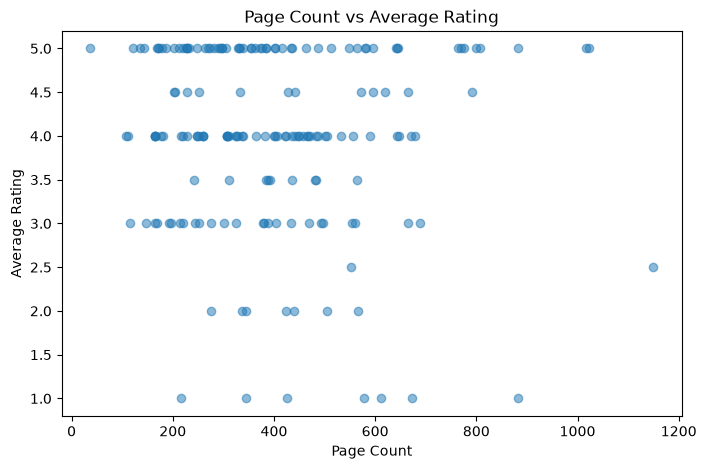

Correlation: -0.06943844482257948


In [7]:
# Does page count relate to rating?
rated = df[df["avg_rating"].notna()]
print(f"Rated books: {len(rated)}")

plt.figure(figsize=(8,5))
plt.scatter(rated["page_count"], rated["avg_rating"], alpha=0.5)
plt.xlabel("Page Count")
plt.ylabel("Average Rating")
plt.title("Page Count vs Average Rating")
plt.show()

print("Correlation:", rated["page_count"].corr(rated["avg_rating"]))

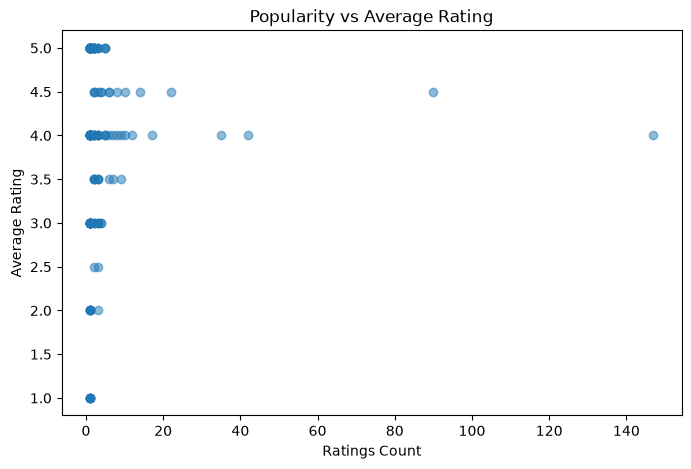

Correlation: 0.02196006620035876


In [8]:
# Does popularity (ratings_count) relate to rating?
plt.figure(figsize=(8,5))
plt.scatter(rated["ratings_count"], rated["avg_rating"], alpha=0.5)
plt.xlabel("Ratings Count")
plt.ylabel("Average Rating")
plt.title("Popularity vs Average Rating")
plt.show()

print("Correlation:", rated["ratings_count"].corr(rated["avg_rating"]))

In [9]:
# Does rating vary by category? (top 8 categories only, for readability)
top_cats = df["primary_category"].value_counts().head(8).index
rated_top = rated[rated["primary_category"].isin(top_cats)]

rated_top.groupby("primary_category")["avg_rating"].agg(["mean", "count"]).sort_values("mean", ascending=False)

,mean,count
primary_category,,
Science,4.700000,5
Juvenile Fiction,4.406250,16
Business & Economics,4.071429,14
Fiction,3.964912,57
Cooking,3.937500,8
History,3.807692,13
Philosophy,3.400000,5
Biography & Autobiography,3.363636,11
